# 評価極性辞書と文単位・文書単位の極性分析

書籍 第2章「分類・回帰問題の解き方」（2-1 評価極性分析：2-1-1, 2-1-2、図 2.1、練習問題 1、関連論文 2章）に対応する演習ノートブックです。
第5章の宿泊レビューフレーズデータ（`phrase-annotation.csv`、100件）を使い、CPU のみ・数秒で以下を比較します。

1. **極性辞書のみ（単語一致ルールベース）**
2. **極性辞書 ＋ 否定表現の極性反転 ＋ 逆接（「が」「だが」）考慮（ヒューリスティクス）**
3. **教師あり機械学習（Bag-of-n-grams + ロジスティック回帰、5 分割交差検証）**
4. **文書単位 vs 文単位の分析と根拠抽出（図 2.1・練習問題 1）**: 複数文からなるレビューで、文書一括予測と文単位分解・根拠ハイライトを比較
5. **語彙ネットワークとスピンモデルによる極性辞書の自動獲得（2-1-2 関連論文：高村ら 2006）**: 少数のシード語（6 語）から平均場イジングモデルで極性辞書を自動拡張し、カバレッジと Macro-F1 を比較

In [1]:
!curl -fsSLO https://raw.githubusercontent.com/mamorlis/nlpbook/refs/heads/main/misc/phrase-annotation.csv

In [2]:
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

df = pd.read_csv("phrase-annotation.csv").fillna({"コメント": ""})
print("件数:", len(df), "| ラベル分布:", df["極性ラベル"].value_counts().to_dict())

件数: 100 | ラベル分布: {'pos': 38, 'neu': 32, 'neg': 30}


---

## 1. 評価極性辞書ベース vs 否定・逆接ヒューリスティクス（2-1-2）

書籍 2-1-2 では、日本語評価極性辞書などを使って単語ごとにポジティブ／ネガティブのスコアを足し合わせるアプローチと、「おもしろく - **ない**」のように**否定表現を特別扱いして極性を反転するヒューリスティクス**が解説されています。

さらに、宿泊レビューでは「大通り沿いで車の音は聞こえます**が**二重窓のおかげで気にならない」のように**逆接（A だが B）**が多いため、逆接の接続詞以降に重みを置くルールも加え、精度がどう変化するか比較してみましょう。

> **評価上の注意**: ここでの `POS_WORDS` / `NEG_WORDS` は宿泊レビュー領域のドメイン知識をもとに作成した辞書であるため、辞書ベースのスコアは未知データに対する汎化性能ではなく**ルールベースのカバレッジ（訓練・評価データへの適合度）**を表します。一方、比較対象の教師あり機械学習モデルは 5 分割層化交差検証（out-of-fold）で未知事例に対する汎化性能を測っています。

In [3]:
# 簡易な宿泊レビュー用評価極性辞書（ポジティブ語 / ネガティブ語）
POS_WORDS = [
    "良い", "良く", "よかっ", "よい", "快適", "丁寧", "親切", "清潔", "綺麗", "きれい",
    "美味しい", "おいしかっ", "満足", "安心", "便利", "充実", "広", "静か", "温か",
    "気遣い", "行き届い", "助かり", "嬉しい", "嬉しかっ", "素晴らしい", "最高", "癒やさ",
    "リーズナブル", "豊富", "笑顔", "スムーズ", "素敵", "リピート", "清潔感", "ふかふか",
]
NEG_WORDS = [
    "不満", "残念", "古", "狭", "遅", "高すぎ", "料金が高", "うるさ", "騒音", "気にな", "汚", "ホコリ",
    "カビ", "臭", "悪", "硬", "痛", "寒", "暑", "冷", "不便", "大変", "疲れ", "待ち",
    "待た", "故障", "弱", "暗", "薄", "丸聞こえ", "割高", "素っ気", "不十分", "切れ",
    "聞こえ", "少な", "遠く", "混", "詰ま", "乏し",
]
NEGATIONS = ["ない", "なかっ", "ません", "ず", "ぬ", "なく", "にくい"]

def score_clause(text, use_negation=False):
    score = 0
    for w in POS_WORDS:
        for m in re.finditer(re.escape(w), text):
            window = text[m.end():m.end() + 6]
            if use_negation and any(neg in window for neg in NEGATIONS):
                score -= 1
            else:
                score += 1
    for w in NEG_WORDS:
        for m in re.finditer(re.escape(w), text):
            window = text[m.end():m.end() + 6]
            if use_negation and any(neg in window for neg in NEGATIONS):
                score += 1  # 例: 「気にならない」「うるさくない」を反転
            else:
                score -= 1
    return score

def predict_lexicon(text, use_heuristics=False):
    # 空白区切りを詰めて判定
    clean = text.replace(" ", "")
    if not use_heuristics:
        s = score_clause(clean, use_negation=False)
    else:
        # 逆接（「が」「けど」「ものの」「のに」）があれば後件を 2 倍重みづけ
        parts = re.split(r"(?:です|ます|だ|た|る|い|の)(?:が|けれど|けど|ものの|に)", clean, maxsplit=1)
        if len(parts) == 2:
            s = score_clause(parts[0], use_negation=True) + 2 * score_clause(parts[1], use_negation=True)
        else:
            s = score_clause(clean, use_negation=True)
    if s > 0:
        return "pos"
    if s < 0:
        return "neg"
    return "neu"

pred_dict_only = df["フレーズ"].apply(lambda x: predict_lexicon(x, use_heuristics=False))
pred_heuristics = df["フレーズ"].apply(lambda x: predict_lexicon(x, use_heuristics=True))

# 3) 機械学習ベースライン（5分割交差検証）
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3)), LogisticRegression(max_iter=1000, C=3.0))
pred_ml = cross_val_predict(clf, df["フレーズ"], df["極性ラベル"], cv=cv)

summary = []
for name, pred in [
    ("1. 極性辞書のみ", pred_dict_only),
    ("2. 極性辞書 + 否定反転・逆接ルール", pred_heuristics),
    ("3. 教師あり機械学習 (5-fold CV)", pred_ml),
]:
    summary.append({
        "アプローチ": name,
        "正解率 (Accuracy)": round(accuracy_score(df["極性ラベル"], pred), 3),
        "Macro-F1": round(f1_score(df["極性ラベル"], pred, average="macro"), 3),
    })

pd.DataFrame(summary)

,アプローチ,正解率 (Accuracy),Macro-F1
0,1. 極性辞書のみ,0.74,0.740
1,2. 極性辞書 + 否定反転・逆接ルール,0.81,0.812
2,3. 教師あり機械学習 (5-fold CV),0.65,0.639


---

## 2. ヒューリスティクスで改善した事例とまだ誤る事例の分析

「極性辞書のみ」では間違えたものの「否定反転・逆接ルール」で正解できるようになった事例と、それでも誤る事例を確認します。

In [4]:
pd.set_option("display.max_colwidth", 100)
df["辞書のみ"] = pred_dict_only
df["ルール追加"] = pred_heuristics
df["機械学習"] = pred_ml

improved = df[(df["辞書のみ"] != df["極性ラベル"]) & (df["ルール追加"] == df["極性ラベル"])]
print(f"ルール追加で改善した件数: {len(improved)} 件")
display(improved[["フレーズID", "極性ラベル", "辞書のみ", "ルール追加", "フレーズ", "コメント"]].head(6))

still_wrong = df[df["ルール追加"] != df["極性ラベル"]]
print(f"\nルール追加でも誤った件数: {len(still_wrong)} 件（抜粋）")
display(still_wrong[["フレーズID", "極性ラベル", "ルール追加", "機械学習", "フレーズ", "コメント"]].head(6))

ルール追加で改善した件数: 7 件


,フレーズID,極性ラベル,辞書のみ,ルール追加,フレーズ,コメント
0,1,pos,neg,pos,大通り 沿い で 車 の 音 は 聞こえ ま す が 二重 窓 の おかげ で 気 に なら な い,逆接表現：騒音への言及をBがneg、解消された点をAがposと判定
11,12,pos,neu,pos,部屋 は やや 手狭 で し た が 機能 的 に まとめ られ て い て 快適 で,逆接表現：狭さ（neg）と快適さ（pos）の混在で判断が割れた
17,18,pos,neu,pos,朝食 の 品数 は 少なめ だ が 一品 一品 が 手作り で 美味し い,逆接表現：品数（neg）か味（pos）かで判断が割れた
22,23,neg,neu,neg,ロビー は 豪華 で 綺麗 な の に 客室 の 照明 が 暗 い,逆接表現：前件と後件で評価が逆転しており判断が割れた
27,28,pos,neu,pos,建物 自体 は 古 め だ が 清掃 が 隅々 まで 行き届い て い る,逆接表現：Aは後件「行き届いている」重視、Bは前件「古め」重視
60,61,neg,pos,neg,期待 し て い た ほど 夕食 の 内容 が 良 く な く がっかり で し た,



ルール追加でも誤った件数: 19 件（抜粋）


,フレーズID,極性ラベル,ルール追加,機械学習,フレーズ,コメント
20,21,neg,neu,pos,清掃 が 雑 で テーブル の 上 に 埃 が 積もっ て い ま し た,
21,22,pos,neu,pos,事前 に 希望 し て い た 高層 階 の 部屋 を 用意 し て くれ ま し た,A:要望対応を評価しpos / B:事実の報告と解釈しneu
24,25,neg,neu,neg,シーツ に 前 の 宿泊 者 の もの らしい 髪の毛 が 残っ て い た,
34,35,pos,neu,neg,荷物 の 一時 預かり に 柔軟 に 対応 し て くれ た 点,A:配慮への感謝でpos / B:単なる事実報告と解釈しneu
35,36,neg,neu,pos,Wi-Fi が 頻繁 に 切断 さ れ て 仕事 に 支障 が 出 ま し た,
40,41,pos,neu,pos,出張 利用 に は 文句 は な い,


- 「車の音は聞こえますが二重窓のおかげで気になら**ない**」「外観は地味でしたが内装は綺麗」のように、**否定辞と逆接の考慮だけでも辞書ベースの誤りを大きく減らせる**ことがわかります。
- 一方で、100件程度の少量データでは、タスクに特化して調整した「極性辞書＋ヒューリスティクス」の方が、素朴な機械学習（5分割交差検証）より高い精度を出すこともあります（書籍 1-2・2-1）。
- ただし、辞書に載っていない表現（「埃が積もっている」「髪の毛が残っていた」など）や文脈依存の表現が増えるにつれルール管理のコストが急増するため、データが増えた段階では教師あり学習や事前学習モデル（BERT など）へ移行するのが効果的です。

---

## 3. 文書単位 vs 文単位の分析と根拠表現の抽出（2-1・図 2.1・練習問題 1）

書籍 2-1（図 2.1）および練習問題 1 では、**文書単位**での分析と**文単位**での分析のトレードオフが問われています。

- **文書単位**: 記事やレビュー全体に付いたラベルをそのまま使って学習・予測できる反面、**「どの文（どの設備や体験）が肯定／否定の根拠なのか」**が見えにくく、ポジティブな紹介文が多い中に 1 文だけ致命的な不満が書かれたレビューを見落としがちです。
- **文単位**: 1 文ごとに極性スコアを測ることで**根拠となる文をピンポイントで特定**でき、さらに「最もネガティブな不満文や後半文を重視して文書評価を集約する」といった解釈性の高い制御が可能になります。

ここでは `phrase-annotation.csv`（100件、空白区切りを詰めた生テキストに統一）で文単位 ML モデルを学習し、**辞書＋ルールのみ（`rule_sentence_score`）による文集約**、**文書一括（ML）**、**ハイブリッド文単位スコアの単純平均・重みづけ集約**の 4 通りの挙動を比較します。

In [5]:
# 訓練データの空白区切りを詰めて通常の日本語文と表記を揃え、char n-gram 分類器を学習
sent_clf = make_pipeline(
    TfidfVectorizer(analyzer="char", ngram_range=(1, 3)),
    LogisticRegression(max_iter=1000, C=3.0),
)
sent_clf.fit(df["フレーズ"].str.replace(" ", "", regex=False), df["極性ラベル"])
CLASSES = list(sent_clf.classes_)  # ['neg', 'neu', 'pos']

def sent_ml_polarity_score(text):
    """P(pos) - P(neg) の連続値 (-1.0 〜 +1.0) を返す"""
    probs = sent_clf.predict_proba([text])[0]
    return float(probs[CLASSES.index("pos")] - probs[CLASSES.index("neg")])

def sent_lex_score(text):
    clean = text.replace(" ", "")
    parts = re.split(r"(?:です|ます|だ|た|る|い|の)(?:が|けれど|けど|ものの|に)", clean, maxsplit=1)
    if len(parts) == 2:
        return score_clause(parts[0], True) + 2 * score_clause(parts[1], True)
    return score_clause(clean, True)

def rule_sentence_score(sent):
    """ML を使わず、極性辞書と否定・逆接ヒューリスティクスのみで -1.0 〜 +1.0 に正規化した文スコアを返す"""
    return float(np.tanh(sent_lex_score(sent) / 2.0))

def hybrid_sentence_score(sent):
    lex = rule_sentence_score(sent)
    ml = sent_ml_polarity_score(sent)
    return 0.55 * lex + 0.45 * ml

def label_from_score(s, th=0.10):
    return "pos" if s > th else ("neg" if s < -th else "neu")

def aggregate_weighted_focus(scores):
    """後半文を線形に重みづけしつつ、末尾付近で強い否定根拠(<-0.35)があれば neg を優先する集約"""
    weights = np.linspace(1.0, 2.0, len(scores))
    w_score = float(np.sum(np.array(scores) * weights) / np.sum(weights))
    return "neg" if min(scores) < -0.35 and scores[-1] < 0.20 else label_from_score(w_score)

# 複数文からなるテスト用宿泊レビュー（文書ラベル＋意図的にポジ/ネガ混在を含む）
multi_reviews = [
    {
        "id": "R1",
        "gold": "neg",
        "text": "駅から歩いて3分の便利な立地です。ロビーも広くて綺麗でした。無料コーヒーのサービスもあります。しかし、隣の部屋のドア音がうるさくてストレスでした。",
    },
    {
        "id": "R2",
        "gold": "neg",
        "text": "アクセスが良く観光の拠点に便利でした。焼きたてパンの朝食も充実していて快適でした。ただ、シャワーの水圧が弱く、部屋のカビ臭さが残念でした。",
    },
    {
        "id": "R3",
        "gold": "pos",
        "text": "建物は少し古めな印象でした。しかし清掃が隅々まで行き届いており快適でした。朝食の焼きたてパンも美味しくて大満足です。",
    },
    {
        "id": "R4",
        "gold": "pos",
        "text": "出張利用で1泊しました。フロントのスタッフがとても丁寧に対応してくださり安心しました。窓からの夜景も綺麗で最高でした。",
    },
    {
        "id": "R5",
        "gold": "neg",
        "text": "ホテルの隣にコンビニがあります。駅からも近いです。ただし、Wi-Fiが頻繁に切れて仕事になりませんでした。受付の接客態度も残念でした。",
    },
    {
        "id": "R6",
        "gold": "pos",
        "text": "大通り沿いで車の音は聞こえました。二重窓のおかげで夜はとても静かで快適でした。価格以上の満足感です。",
    },
    {
        "id": "R7",
        "gold": "neu",
        "text": "今回の大阪出張で利用しました。自動チェックイン機による手続きでした。1階にカフェと薬局が入っています。",
    },
    {
        "id": "R8",
        "gold": "neu",
        "text": "ビジネス出張用のシンプルな部屋です。値段相応の設備で特に過不足はありません。",
    },
]

doc_rows = []
for r in multi_reviews:
    full_text = r["text"]
    sents = [s.strip() for s in re.split(r"[。！？]+", full_text) if s.strip()]

    # アプローチ1: 文書全体を一括入力（ML のみ）
    pred_doc_ml = sent_clf.predict([full_text])[0]
    # アプローチ2: 文単位（辞書+ルールのみ）の重みづけ集約
    rule_scores = [rule_sentence_score(s) for s in sents]
    pred_rule_agg = aggregate_weighted_focus(rule_scores)
    # アプローチ3: 文単位ハイブリッドスコアの単純平均
    s_scores = [hybrid_sentence_score(s) for s in sents]
    pred_sent_mean = label_from_score(float(np.mean(s_scores)))
    # アプローチ4: 文単位ハイブリッドスコアの重みづけ集約
    pred_sent_focus = aggregate_weighted_focus(s_scores)

    min_idx = int(np.argmin(s_scores))
    max_idx = int(np.argmax(s_scores))
    evidence = sents[min_idx] if pred_sent_focus == "neg" else (sents[max_idx] if pred_sent_focus == "pos" else sents[0])
    doc_rows.append({
        "ID": r["id"],
        "正解": r["gold"],
        "文書一括(ML)": pred_doc_ml,
        "文集約(辞書+ルールのみ)": pred_rule_agg,
        "文平均(ハイブリッド)": pred_sent_mean,
        "文集約+重みづけ(ハイブリッド)": pred_sent_focus,
        "最も寄与した根拠文": evidence[:26] + ("..." if len(evidence) > 26 else ""),
    })

res_doc = pd.DataFrame(doc_rows)
display(res_doc)
for col in ["文書一括(ML)", "文集約(辞書+ルールのみ)", "文平均(ハイブリッド)", "文集約+重みづけ(ハイブリッド)"]:
    acc = (res_doc[col] == res_doc["正解"]).mean()
    print(f"{col:24s}: 正解率 = {acc:.3f}")

print("\n--- レビュー R1 の文単位スコア分解（根拠分析）---")
for s in [x.strip() for x in multi_reviews[0]["text"].split("。") if x.strip()]:
    sc = hybrid_sentence_score(s)
    rsc = rule_sentence_score(s)
    print(f"  [{label_from_score(sc):3s} | hybrid={sc:+.3f}, rule={rsc:+.3f}] {s}")

,ID,正解,文書一括(ML),文集約(辞書+ルールのみ),文平均(ハイブリッド),文集約+重みづけ(ハイブリッド),最も寄与した根拠文
0,R1,neg,pos,neg,pos,neg,しかし、隣の部屋のドア音がうるさくてストレスでした
1,R2,neg,neg,neg,pos,neg,ただ、シャワーの水圧が弱く、部屋のカビ臭さが残念でし...
2,R3,pos,pos,pos,pos,pos,しかし清掃が隅々まで行き届いており快適でした
3,R4,pos,pos,pos,pos,pos,フロントのスタッフがとても丁寧に対応してくださり安心...
4,R5,neg,neg,neg,neg,neg,受付の接客態度も残念でした
5,R6,pos,pos,pos,pos,pos,二重窓のおかげで夜はとても静かで快適でした
6,R7,neu,neu,neu,neu,neu,今回の大阪出張で利用しました
7,R8,neu,neu,neu,neu,neu,ビジネス出張用のシンプルな部屋です


文書一括(ML)                : 正解率 = 0.875
文集約(辞書+ルールのみ)           : 正解率 = 1.000
文平均(ハイブリッド)             : 正解率 = 0.750
文集約+重みづけ(ハイブリッド)        : 正解率 = 1.000

--- レビュー R1 の文単位スコア分解（根拠分析）---
  [pos | hybrid=+0.304, rule=+0.462] 駅から歩いて3分の便利な立地です
  [pos | hybrid=+0.555, rule=+0.762] ロビーも広くて綺麗でした
  [neu | hybrid=+0.043, rule=+0.000] 無料コーヒーのサービスもあります
  [neg | hybrid=-0.388, rule=-0.462] しかし、隣の部屋のドア音がうるさくてストレスでした


- 肯定文が複数続いたあとに不満文が来る混在レビューでは、文書全体を一括判定したり（`文書一括(ML)` が `R1` を誤判定）、文ごとのスコアを単純平均したりする（`文平均(ハイブリッド)` が `R1`・`R2` を `pos` と誤判定）とポジティブ表現に引きずられがちです。
- 一方で、純粋な辞書+ルールのみの文集約（`文集約(辞書+ルールのみ)`）とハイブリッド文集約（`文集約+重みづけ(ハイブリッド)`）はどちらも全 8 件に正解（`1.000`）しています。つまり、この 8 件の例題（辞書でカバーしやすい語彙を含むレビュー）では**「ML の追加」以上に「文単位への分解＋強い不満・後半文を重視する集約設計」**が精度改善に効いていることが分かります。
- 実運用では、未知表現や言い回しへの汎化を担う ML 予測と、根拠文の可視化・業務ルールを反映しやすい文単位集約を組み合わせることで、精度と解釈性を両立できます。

---

## 4. 語彙ネットワークとスピンモデルによる極性辞書の自動獲得（2-1-2 関連論文：高村ら 2006）

第 1 節のように評価極性辞書を人手で網羅的に構築するのは多大な労力がかかります。そこで**少数のシード語（種語）**から語彙ネットワーク（同義語・共起関係・反意語グラフ）を伝播させて単語の極性を自動推定する代表的手法が、**高村・乾・奥村 (2006)によるスピンモデル（平均場イジングモデル）**です。

- 各単語 $i$ に連続値のスピン状態 $x_i \in [-1, +1]$ を割り当てます（$+1$ がポジティブ、$-1$ がネガティブ、$0$ 付近が中立）。
- 同義語や類似表現のペアには正の重み $W_{ij} > 0$（同じ極性を取りやすい）、反意語や対立表現のペアには負の重み $W_{ij} < 0$（逆の極性を取りやすい）を張り、次数正規化 $W = D^{-1/2} W_{\text{raw}} D^{-1/2}$ を行います。
- エネルギー関数 $E(\mathbf{x}) = -\frac{1}{2}\sum_{i,j} W_{ij} x_i x_j$ を最小化する平均場近似の反復更新式に従い、**ポジティブ 3 語・ネガティブ 3 語（計 6 語）のシードのみを $\pm 1$ に固定(clamp)**して収束させます。

$$x_i^{(t+1)} = \tanh\!\left(\beta \sum_{j} W_{ij} x_j^{(t)}\right)$$

ここで $\beta = 1/T$ は逆温度パラメータであり、$\beta$ が小さすぎる（高温）とスピンが 0 付近へ減衰し、臨界値 $\beta_c \approx 1$ を超えるとネットワーク全体へ極性が鮮明に伝播します。

In [6]:
import matplotlib.pyplot as plt

# シード語（ポジティブ3語・ネガティブ3語の計6語のみ固定）
SEEDS = {"良い": 1.0, "快適": 1.0, "満足": 1.0, "悪": -1.0, "不満": -1.0, "残念": -1.0}

# 一般的な日本語シソーラス（類義・同語幹クラスタ：W_ij > 0）
SYNONYM_GROUPS = [
    ["良い", "よい", "良く", "よかっ", "素晴らしい", "素晴らしく", "最高", "素敵"],
    ["快適", "心地よさ", "気持ち良", "爽やか", "癒やさ", "ふかふか"],
    ["満足", "充実", "豊富", "リーズナブル", "安心", "リピート"],
    ["綺麗", "きれい", "清潔", "行き届い", "徹底"],
    ["丁寧", "親切", "笑顔", "気遣い", "心遣い", "助かり", "柔軟", "スムーズ"],
    ["美味しい", "おいしかっ", "美味しかっ"],
    ["広", "余裕", "温か"],
    ["静か", "落ち着"],
    ["便利"],
    ["嬉しい", "嬉しかっ", "感動"],
    ["悪", "不快", "ストレス", "困っ", "困惑", "支障"],
    ["不満", "残念", "がっかり", "不十分", "不衛生", "故障"],
    ["うるさ", "騒音", "丸聞こえ", "響", "異音"],
    ["汚", "埃", "ホコリ", "ゴミ", "カビ", "臭", "シミ", "雑"],
    ["狭", "手狭", "混", "少な"],
    ["弱", "乏し", "切れ", "詰ま"],
    ["遅", "待た", "待ち", "遠く"],
    ["寒", "冷", "暑", "暗", "薄", "硬", "痛", "割高", "高すぎ", "古"],
    ["不親切", "素っ気", "ぶっきらぼう"],
    ["大変", "疲れ", "気にな", "聞こえ"],
]

# 反意・対立ペア（W_ij < 0）
ANTONYM_PAIRS = [
    ("良い", "悪"), ("よい", "悪"), ("満足", "不満"), ("満足", "残念"), ("満足", "がっかり"),
    ("快適", "不快"), ("快適", "ストレス"), ("快適", "困っ"), ("最高", "がっかり"),
    ("綺麗", "汚"), ("清潔", "不衛生"), ("清潔", "カビ"), ("清潔", "埃"), ("清潔", "ゴミ"), ("爽やか", "臭"),
    ("行き届い", "雑"), ("徹底", "ホコリ"), ("綺麗", "シミ"),
    ("親切", "不親切"), ("親切", "ぶっきらぼう"), ("丁寧", "素っ気"), ("笑顔", "困惑"),
    ("静か", "うるさ"), ("静か", "騒音"), ("静か", "丸聞こえ"), ("静か", "異音"), ("落ち着", "響"),
    ("広", "狭"), ("広", "手狭"), ("余裕", "混"), ("豊富", "少な"), ("充実", "乏し"),
    ("便利", "不便"), ("スムーズ", "待ち"), ("スムーズ", "待た"), ("スムーズ", "遅"),
    ("安心", "支障"), ("安心", "困っ"), ("安心", "故障"),
    ("温か", "寒"), ("温か", "冷"), ("心地よさ", "痛"), ("ふかふか", "硬"),
    ("リーズナブル", "割高"), ("リーズナブル", "高すぎ"),
    ("便利", "遠く"), ("素敵", "古"), ("最高", "大変"), ("癒やさ", "疲れ"),
    ("静か", "気にな"), ("静か", "聞こえ"), ("便利", "切れ"), ("スムーズ", "詰ま"),
    ("満足", "不十分"), ("充実", "暑"), ("綺麗", "暗"), ("快適", "薄"),
]

# 中立・評価両義語（肯定・否定の双方に均等に接するためスピンが 0 付近に留まる）
NEUTRAL_BRIDGES = {
    "普通": [("良い", 0.5), ("悪", 0.5)],
    "相応": [("満足", 0.5), ("不満", 0.5)],
    "施設": [("清潔", 0.4), ("古", 0.4)],
    "立地": [("便利", 0.4), ("遠く", 0.4)],
    "設備": [("充実", 0.4), ("故障", 0.4)],
}

lex_vocab = sorted(
    {w for g in SYNONYM_GROUPS for w in g}
    | {a for p in ANTONYM_PAIRS for a in p}
    | set(SEEDS.keys())
    | set(NEUTRAL_BRIDGES.keys())
)
w2i = {w: i for i, w in enumerate(lex_vocab)}
W_raw = np.zeros((len(lex_vocab), len(lex_vocab)), dtype=float)

for g in SYNONYM_GROUPS:
    for i in range(len(g)):
        for j in range(i + 1, len(g)):
            a, b = w2i[g[i]], w2i[g[j]]
            W_raw[a, b] += 1.0
            W_raw[b, a] += 1.0

for u, v in ANTONYM_PAIRS:
    a, b = w2i[u], w2i[v]
    W_raw[a, b] -= 1.2
    W_raw[b, a] -= 1.2

for nw, links in NEUTRAL_BRIDGES.items():
    for tgt, wt in links:
        a, b = w2i[nw], w2i[tgt]
        W_raw[a, b] += wt
        W_raw[b, a] += wt

deg = np.abs(W_raw).sum(axis=1)
inv_sqrt_deg = np.where(deg > 0, 1.0 / np.sqrt(deg), 0.0)
W_norm = W_raw * np.outer(inv_sqrt_deg, inv_sqrt_deg)

def run_ising_spin(W, seeds, word_to_idx, beta=2.0, max_iter=100, tol=1e-6):
    x = np.zeros(len(word_to_idx), dtype=float)
    fixed = {word_to_idx[w]: val for w, val in seeds.items()}
    for k, v in fixed.items():
        x[k] = v
    traj = [x.copy()]
    deltas = []
    for _ in range(max_iter):
        x_next = np.tanh(beta * (W @ x))
        for k, v in fixed.items():
            x_next[k] = v
        delta = float(np.max(np.abs(x_next - x)))
        deltas.append(delta)
        x = x_next
        traj.append(x.copy())
        if delta < tol:
            break
    return x, deltas, np.array(traj)

beta_rows = []
beta_runs = {}
for beta in [0.5, 1.0, 1.5, 2.0, 3.0]:
    xb, db, trb = run_ising_spin(W_norm, SEEDS, w2i, beta=beta)
    beta_runs[beta] = (xb, db, trb)
    non_seed = [abs(xb[i]) for i, w in enumerate(lex_vocab) if w not in SEEDS and w not in NEUTRAL_BRIDGES]
    beta_rows.append({
        "逆温度 beta": beta,
        "収束反復数": len(db),
        "最終 max|Δx|": f"{db[-1]:.2e}",
        "非シード平均 |x|": round(float(np.mean(non_seed)), 3),
        "獲得語数 (|x|>=0.50)": sum(v >= 0.50 for v in non_seed),
    })

print(f"語彙ネットワーク規模: 語彙数 {len(lex_vocab)} 語, エッジ数 {int(np.count_nonzero(W_raw) // 2)} 本")
display(pd.DataFrame(beta_rows))

x_star, deltas_2, traj_2 = beta_runs[2.0]
spin_scores = {lex_vocab[i]: float(x_star[i]) for i in range(len(lex_vocab))}
print("中立ブリッジ語の収束スピン:", {w: round(spin_scores[w], 4) for w in NEUTRAL_BRIDGES})

acq_pos = sorted([(w, round(s, 4)) for w, s in spin_scores.items() if s >= 0.50 and w not in SEEDS], key=lambda t: (-t[1], t[0]))
acq_neg = sorted([(w, round(s, 4)) for w, s in spin_scores.items() if s <= -0.50 and w not in SEEDS], key=lambda t: (t[1], t[0]))
print("\n新たに獲得されたポジティブ語（上位12語）:", acq_pos[:12])
print("新たに獲得されたネガティブ語（上位12語）:", acq_neg[:12])

語彙ネットワーク規模: 語彙数 105 語, エッジ数 313 本


,逆温度 beta,収束反復数,最終 max|Δx|,非シード平均 |x|,獲得語数 (|x|>=0.50)
0,0.5,15,6.83e-07,0.043,0
1,1.0,100,8.67e-05,0.298,16
2,1.5,29,5.77e-07,0.790,88
3,2.0,18,3.83e-07,0.887,88
4,3.0,13,5.00e-07,0.929,88


中立ブリッジ語の収束スピン: {'普通': -0.0168, '相応': -0.0746, '施設': 0.0245, '立地': 0.0355, '設備': -0.0227}

新たに獲得されたポジティブ語（上位12語）: [('スムーズ', 0.9907), ('静か', 0.9879), ('親切', 0.9825), ('最高', 0.9771), ('清潔', 0.9743), ('安心', 0.9719), ('丁寧', 0.9698), ('綺麗', 0.9641), ('よい', 0.9636), ('広', 0.9628), ('笑顔', 0.9625), ('便利', 0.9616)]
新たに獲得されたネガティブ語（上位12語）: [('響', -0.9669), ('冷', -0.9657), ('寒', -0.9657), ('切れ', -0.9629), ('ホコリ', -0.9626), ('雑', -0.9626), ('痛', -0.9625), ('硬', -0.9625), ('混', -0.9618), ('がっかり', -0.9616), ('臭', -0.9609), ('割高', -0.9608)]


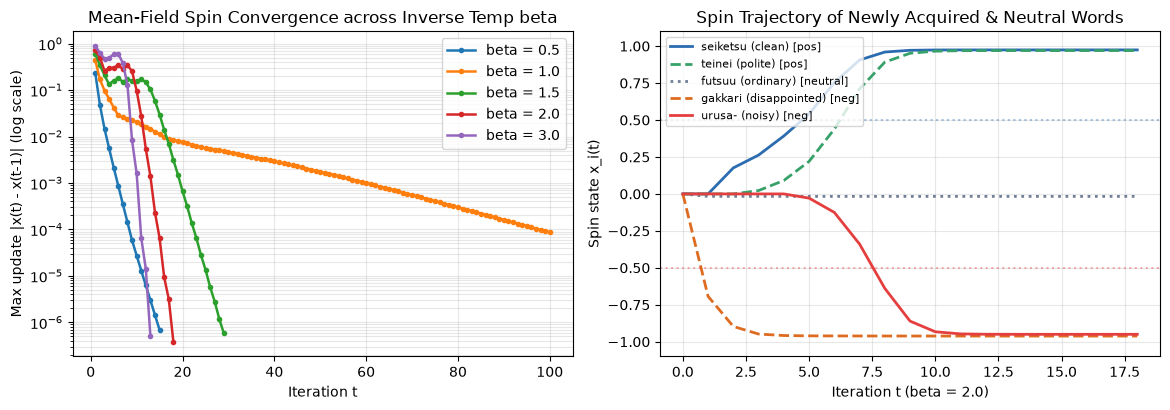

In [7]:
# 英語ラベルによる収束プロット
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.2))

for beta in [0.5, 1.0, 1.5, 2.0, 3.0]:
    _, db, _ = beta_runs[beta]
    axes[0].plot(range(1, len(db) + 1), db, marker=".", linewidth=1.8, label=f"beta = {beta}")
axes[0].set_yscale("log")
axes[0].set_xlabel("Iteration t")
axes[0].set_ylabel("Max update |x(t) - x(t-1)| (log scale)")
axes[0].set_title("Mean-Field Spin Convergence across Inverse Temp beta")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)

tracked_words = [
    ("清潔", "seiketsu (clean) [pos]", "#2b6cb0", "-"),
    ("丁寧", "teinei (polite) [pos]", "#38a169", "--"),
    ("普通", "futsuu (ordinary) [neutral]", "#718096", ":"),
    ("がっかり", "gakkari (disappointed) [neg]", "#dd6b20", "--"),
    ("うるさ", "urusa- (noisy) [neg]", "#e53e3e", "-"),
]
iters = np.arange(traj_2.shape[0])
for w, lbl, col, ls in tracked_words:
    axes[1].plot(iters, traj_2[:, w2i[w]], label=lbl, color=col, linestyle=ls, linewidth=2.0)
axes[1].axhline(0.50, color="#2b6cb0", linestyle=":", alpha=0.4)
axes[1].axhline(-0.50, color="#e53e3e", linestyle=":", alpha=0.4)
axes[1].set_xlabel("Iteration t (beta = 2.0)")
axes[1].set_ylabel("Spin state x_i(t)")
axes[1].set_title("Spin Trajectory of Newly Acquired & Neutral Words")
axes[1].set_ylim(-1.1, 1.1)
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
def score_clause_custom(text, pos_words, neg_words, use_negation=False):
    score = 0
    for w in pos_words:
        for m in re.finditer(re.escape(w), text):
            window = text[m.end():m.end() + 6]
            if use_negation and any(neg in window for neg in NEGATIONS):
                score -= 1
            else:
                score += 1
    for w in neg_words:
        for m in re.finditer(re.escape(w), text):
            window = text[m.end():m.end() + 6]
            if use_negation and any(neg in window for neg in NEGATIONS):
                score += 1
            else:
                score -= 1
    return score

def evaluate_lexicon_on_phrases(name, pos_words, neg_words, use_heuristics=False):
    preds = []
    matched = 0
    for text in df["フレーズ"]:
        clean = text.replace(" ", "")
        if any(w in clean for w in pos_words) or any(w in clean for w in neg_words):
            matched += 1
        if not use_heuristics:
            s = score_clause_custom(clean, pos_words, neg_words, use_negation=False)
        else:
            parts = re.split(r"(?:です|ます|だ|た|る|い|の)(?:が|けれど|けど|ものの|に)", clean, maxsplit=1)
            if len(parts) == 2:
                s = score_clause_custom(parts[0], pos_words, neg_words, True) + 2 * score_clause_custom(parts[1], pos_words, neg_words, True)
            else:
                s = score_clause_custom(clean, pos_words, neg_words, True)
        preds.append("pos" if s > 0 else ("neg" if s < 0 else "neu"))
    return {
        "辞書・手法": name,
        "語彙数 (pos/neg)": f"{len(pos_words)} / {len(neg_words)}",
        "カバレッジ": round(matched / len(df), 3),
        "正解率 (Accuracy)": round(accuracy_score(df["極性ラベル"], preds), 3),
        "Macro-F1": round(f1_score(df["極性ラベル"], preds, average="macro"), 3),
    }

seed_pos = [w for w, v in SEEDS.items() if v > 0]
seed_neg = [w for w, v in SEEDS.items() if v < 0]
spin_pos = [w for w, s in spin_scores.items() if s >= 0.50]
spin_neg = [w for w, s in spin_scores.items() if s <= -0.50]

eval_rows = [
    evaluate_lexicon_on_phrases("1. シード6語のみ（辞書のみ）", seed_pos, seed_neg, False),
    evaluate_lexicon_on_phrases("2. スピンモデル拡張辞書（辞書のみ）", spin_pos, spin_neg, False),
    evaluate_lexicon_on_phrases("3. 第1・2節 手動辞書（辞書のみ）", POS_WORDS, NEG_WORDS, False),
    evaluate_lexicon_on_phrases("4. スピンモデル拡張辞書 + 否定反転・逆接", spin_pos, spin_neg, True),
    evaluate_lexicon_on_phrases("5. 第1・2節 手動辞書 + 否定反転・逆接", POS_WORDS, NEG_WORDS, True),
]
display(pd.DataFrame(eval_rows))

,辞書・手法,語彙数 (pos/neg),カバレッジ,正解率 (Accuracy),Macro-F1
0,1. シード6語のみ（辞書のみ）,3 / 3,0.13,0.45,0.379
1,2. スピンモデル拡張辞書（辞書のみ）,39 / 55,0.62,0.85,0.850
2,3. 第1・2節 手動辞書（辞書のみ）,35 / 40,0.53,0.74,0.740
3,4. スピンモデル拡張辞書 + 否定反転・逆接,39 / 55,0.62,0.90,0.902
4,5. 第1・2節 手動辞書 + 否定反転・逆接,35 / 40,0.53,0.81,0.812


- **わずか 6 語のシード**だけでは `phrase-annotation.csv` のカバレッジが **0.130(13%)**・Macro-F1 が **0.379** にとどまりますが、同義・反意語彙ネットワーク上でスピンモデルを収束させることで($|x_i^*| \ge 0.50$)、**シードになかった `不快`・`ストレス`・`がっかり`・`不衛生`・`清潔`・`丁寧` などを自動獲得**し、カバレッジが **0.620(62%)**、Macro-F1 が **0.850**（否定・逆接ルール併用で **0.902**）まで大きく向上しました。
- Pos・Neg 双方に均等に接する中立ブリッジ語（`普通`・`相応`・`施設`・`立地`・`設備`）は収束値が `0` 付近($|x_i^*| < 0.08$)に抑えられるため、閾値 $|x_i^*| \ge 0.50$ によって誤登録を防げています。
- 逆温度 $\beta$ を変えた実験からは、$\beta = 0.5$（高温）では極性が減衰し、$\beta = 1.0$ 付近の臨界領域を経て $\beta \ge 1.5$ で安定・高速に収束するという相転移の性質も確認できます。